In [3]:
from pathlib import Path
import sys
import platform

# Current notebook location:
# /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks

NOTEBOOK_DIR = Path.cwd()

# notebooks -> ai-engine -> AthletiQ
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent

# --------------------------------------------------
# Correct project paths
# --------------------------------------------------

SOCCERNET_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "soccernet"
    / "tracking"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "processed"
    / "soccernet_ball_yolo"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "football_ball_detector.pt"
)

print("Python       :", sys.version)
print("Platform     :", platform.platform())
print()
print("Notebook dir :", NOTEBOOK_DIR)
print("Project root :", PROJECT_ROOT)
print()
print("SoccerNet    :", SOCCERNET_ROOT)
print("Output       :", OUTPUT_ROOT)
print("Ball model   :", MODEL_PATH)

Python       : 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Platform     : Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.39

Notebook dir : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks
Project root : /mnt/d/My Projects/AthletiQ/AthletiQ

SoccerNet    : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/soccernet/tracking
Output       : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_yolo
Ball model   : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/football_ball_detector.pt


In [4]:
print("PATH VERIFICATION")
print("=" * 60)

print(f"Project root exists : {PROJECT_ROOT.exists()}")
print(f"SoccerNet exists    : {SOCCERNET_ROOT.exists()}")
print(f"Model exists        : {MODEL_PATH.exists()}")

print()

gameinfos = list(SOCCERNET_ROOT.rglob("gameinfo.ini"))
seqinfos = list(SOCCERNET_ROOT.rglob("seqinfo.ini"))
gt_files = list(SOCCERNET_ROOT.rglob("gt.txt"))

print(f"gameinfo.ini files  : {len(gameinfos)}")
print(f"seqinfo.ini files   : {len(seqinfos)}")
print(f"gt.txt files        : {len(gt_files)}")

PATH VERIFICATION
Project root exists : True
SoccerNet exists    : True
Model exists        : True

gameinfo.ini files  : 106
seqinfo.ini files   : 106
gt.txt files        : 106


In [5]:
sample_sequence = SOCCERNET_ROOT / "train" / "train" / "SNMOT-170"

print("Sample sequence:")
print(sample_sequence)
print()

for path in sorted(sample_sequence.iterdir()):
    print(path.name)

Sample sequence:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/soccernet/tracking/train/train/SNMOT-170

det
gameinfo.ini
gt
img1
seqinfo.ini


In [6]:
print("\nGT file:")
print(sample_sequence / "gt" / "gt.txt")

print("\nFirst 10 GT lines:")
with open(sample_sequence / "gt" / "gt.txt") as f:
    for _ in range(10):
        print(f.readline().strip())


GT file:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/soccernet/tracking/train/train/SNMOT-170/gt/gt.txt

First 10 GT lines:
1,1,219,465,33,97,1,-1,-1,-1
2,1,220,464,36,97,1,-1,-1,-1
3,1,221,462,38,97,1,-1,-1,-1
4,1,222,461,40,97,1,-1,-1,-1
5,1,223,459,43,97,1,-1,-1,-1
6,1,224,458,45,97,1,-1,-1,-1
7,1,226,456,48,97,1,-1,-1,-1
8,1,227,455,47,98,1,-1,-1,-1
9,1,228,453,45,98,1,-1,-1,-1
10,1,229,452,44,98,1,-1,-1,-1


In [7]:
import re
import pandas as pd

sequence_records = []

for gameinfo_path in sorted(SOCCERNET_ROOT.rglob("gameinfo.ini")):
    
    sequence_dir = gameinfo_path.parent
    
    # Read gameinfo
    lines = gameinfo_path.read_text(errors="ignore").splitlines()
    
    ball_track_ids = []
    
    for line in lines:
        line = line.strip()
        
        match = re.match(r"trackletID_(\d+)=\s*ball;", line)
        
        if match:
            ball_track_ids.append(int(match.group(1)))
    
    sequence_records.append({
        "sequence": sequence_dir.name,
        "path": str(sequence_dir),
        "ball_track_ids": ball_track_ids,
        "num_ball_tracks": len(ball_track_ids)
    })

sequence_df = pd.DataFrame(sequence_records)

print("Sequences discovered:", len(sequence_df))
print()
print(sequence_df.head(10))

Sequences discovered: 106

    sequence                                               path  \
0  SNMOT-116  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
1  SNMOT-117  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
2  SNMOT-118  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
3  SNMOT-119  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
4  SNMOT-120  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
5  SNMOT-121  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
6  SNMOT-122  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
7  SNMOT-123  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
8  SNMOT-124  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   
9  SNMOT-125  /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...   

  ball_track_ids  num_ball_tracks  
0           [20]                1  
1        [8, 31]                2  
2       [10, 11]                2  
3        [6, 26]                2  
4            [1]                1  
5           [16]   

In [8]:
print("Ball tracklet coverage")
print("=" * 60)

print(
    "Sequences with ball :",
    (sequence_df["num_ball_tracks"] > 0).sum()
)

print(
    "Sequences without ball:",
    (sequence_df["num_ball_tracks"] == 0).sum()
)

print(
    "Total ball tracklets:",
    sequence_df["num_ball_tracks"].sum()
)

Ball tracklet coverage
Sequences with ball : 106
Sequences without ball: 0
Total ball tracklets: 139


In [9]:
multi_ball = sequence_df[
    sequence_df["num_ball_tracks"] > 1
].copy()

print("Sequences with multiple ball tracklets:", len(multi_ball))

multi_ball[[
    "sequence",
    "ball_track_ids",
    "num_ball_tracks"
]]

Sequences with multiple ball tracklets: 27


,sequence,ball_track_ids,num_ball_tracks
1,SNMOT-117,"[8, 31]",2
2,SNMOT-118,"[10, 11]",2
3,SNMOT-119,"[6, 26]",2
6,SNMOT-122,"[19, 20]",2
20,SNMOT-136,"[12, 25]",2
22,SNMOT-138,"[16, 24, 25]",3
23,SNMOT-139,"[16, 18]",2
28,SNMOT-144,"[16, 24]",2
31,SNMOT-147,"[2, 23]",2
33,SNMOT-149,"[16, 17]",2


In [10]:
sequence_df[
    sequence_df["sequence"] == "SNMOT-170"
]

,sequence,path,ball_track_ids,num_ball_tracks
105,SNMOT-170,/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...,[10],1


In [12]:
ball_annotations = []

for _, seq in sequence_df.iterrows():
    
    gt_path = Path(seq["path"]) / "gt" / "gt.txt"
    
    ball_ids = set(seq["ball_track_ids"])
    
    with gt_path.open(errors="ignore") as f:
        
        for line in f:
            
            parts = line.strip().split(",")
            
            if len(parts) < 6:
                continue
            
            try:
                frame = int(parts[0])
                track_id = int(parts[1])
                x = float(parts[2])
                y = float(parts[3])
                w = float(parts[4])
                h = float(parts[5])
                
            except ValueError:
                continue
            
            if track_id not in ball_ids:
                continue
            
            ball_annotations.append({
                "sequence": seq["sequence"],
                "frame": frame,
                "track_id": track_id,
                "x": x,
                "y": y,
                "width": w,
                "height": h
            })

ball_df = pd.DataFrame(ball_annotations)

print("Ball annotations:", len(ball_df))
print()
print(ball_df.head(10))

Ball annotations: 75060

    sequence  frame  track_id      x      y  width  height
0  SNMOT-116      1        20  474.0  381.0   12.0    11.0
1  SNMOT-116      2        20  474.0  381.0   12.0    11.0
2  SNMOT-116      3        20  474.0  381.0   12.0    11.0
3  SNMOT-116      4        20  474.0  381.0   12.0    11.0
4  SNMOT-116      5        20  474.0  381.0   12.0    11.0
5  SNMOT-116      6        20  474.0  381.0   12.0    11.0
6  SNMOT-116      7        20  474.0  381.0   12.0    11.0
7  SNMOT-116      8        20  474.0  381.0   12.0    11.0
8  SNMOT-116      9        20  474.0  381.0   12.0    11.0
9  SNMOT-116     10        20  474.0  381.0   12.0    11.0


In [13]:
print("BALL ANNOTATION STATISTICS")
print("=" * 60)

print(f"Total ball boxes : {len(ball_df):,}")
print(f"Unique sequences : {ball_df['sequence'].nunique()}")
print(f"Unique track IDs : {ball_df[['sequence', 'track_id']].drop_duplicates().shape[0]}")

print()
print("Width:")
print(ball_df["width"].describe())

print()
print("Height:")
print(ball_df["height"].describe())

BALL ANNOTATION STATISTICS
Total ball boxes : 75,060
Unique sequences : 106
Unique track IDs : 139

Width:
count    75060.000000
mean        15.921596
std          5.458419
min          1.000000
25%         12.000000
50%         15.000000
75%         19.000000
max         52.000000
Name: width, dtype: float64

Height:
count    75060.000000
mean        14.933014
std          5.181623
min          1.000000
25%         11.000000
50%         14.000000
75%         18.000000
max         51.000000
Name: height, dtype: float64


In [14]:
ball_df["area"] = ball_df["width"] * ball_df["height"]

def size_category(row):
    w = row["width"]
    h = row["height"]

    if w <= 4 or h <= 4:
        return "very_small_<=4px"

    elif w <= 8 or h <= 8:
        return "small_5-8px"

    elif w <= 16 or h <= 16:
        return "medium_9-16px"

    elif w <= 32 or h <= 32:
        return "large_17-32px"

    else:
        return "very_large_>32px"


ball_df["size_category"] = ball_df.apply(size_category, axis=1)

size_counts = (
    ball_df["size_category"]
    .value_counts()
    .reindex([
        "very_small_<=4px",
        "small_5-8px",
        "medium_9-16px",
        "large_17-32px",
        "very_large_>32px"
    ])
)

size_percent = (size_counts / len(ball_df) * 100).round(2)

size_distribution = pd.DataFrame({
    "count": size_counts,
    "percentage": size_percent
})

size_distribution

,count,percentage
size_category,,
very_small_<=4px,141,0.19
small_5-8px,5691,7.58
medium_9-16px,47748,63.61
large_17-32px,21379,28.48
very_large_>32px,101,0.13


In [15]:
ball_df["area"].describe()

count    75060.000000
mean       262.096256
std        182.988614
min          5.000000
25%        132.000000
50%        210.000000
75%        336.000000
max       2208.000000
Name: area, dtype: float64

In [16]:
print("Ball area percentiles:")
print(
    ball_df["area"]
    .quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
)

Ball area percentiles:
0.01     42.0
0.05     72.0
0.10     90.0
0.25    132.0
0.50    210.0
0.75    336.0
0.90    484.0
0.95    621.0
0.99    936.0
Name: area, dtype: float64


In [17]:
print("Checking bounding-box validity...")

invalid_boxes = ball_df[
    (ball_df["width"] <= 0) |
    (ball_df["height"] <= 0) |
    (ball_df["x"] < 0) |
    (ball_df["y"] < 0)
]

print("Invalid basic boxes:", len(invalid_boxes))

Checking bounding-box validity...
Invalid basic boxes: 0


In [18]:
boundary_violations = ball_df[
    (ball_df["x"] + ball_df["width"] > 1920) |
    (ball_df["y"] + ball_df["height"] > 1080)
]

print("Boxes exceeding 1920×1080:", len(boundary_violations))

Boxes exceeding 1920×1080: 0


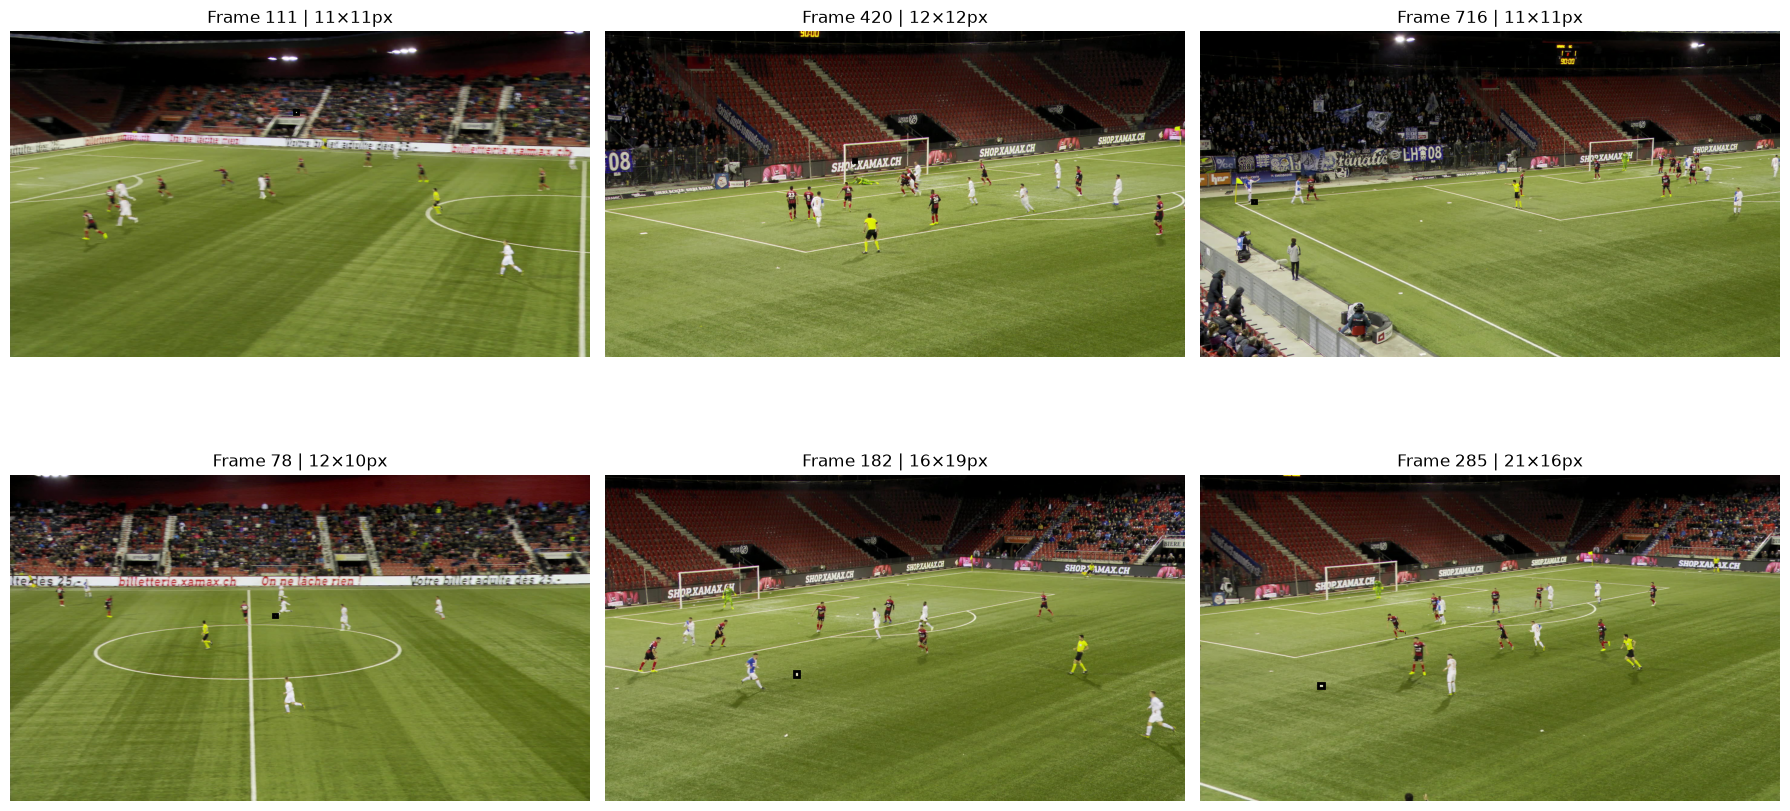

In [19]:
import matplotlib.pyplot as plt
from PIL import Image
import matplotlib.patches as patches

seq_name = "SNMOT-170"

seq_row = sequence_df[
    sequence_df["sequence"] == seq_name
].iloc[0]

img_dir = Path(seq_row["path"]) / "img1"

sample = ball_df[
    ball_df["sequence"] == seq_name
].sample(
    n=6,
    random_state=42
)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):

    image_path = find_image = (
        img_dir / f"{int(row['frame']):06d}.jpg"
    )

    image = Image.open(image_path)

    ax.imshow(image)

    rect = patches.Rectangle(
        (row["x"], row["y"]),
        row["width"],
        row["height"],
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.set_title(
        f"Frame {int(row['frame'])} | "
        f"{row['width']:.0f}×{row['height']:.0f}px"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

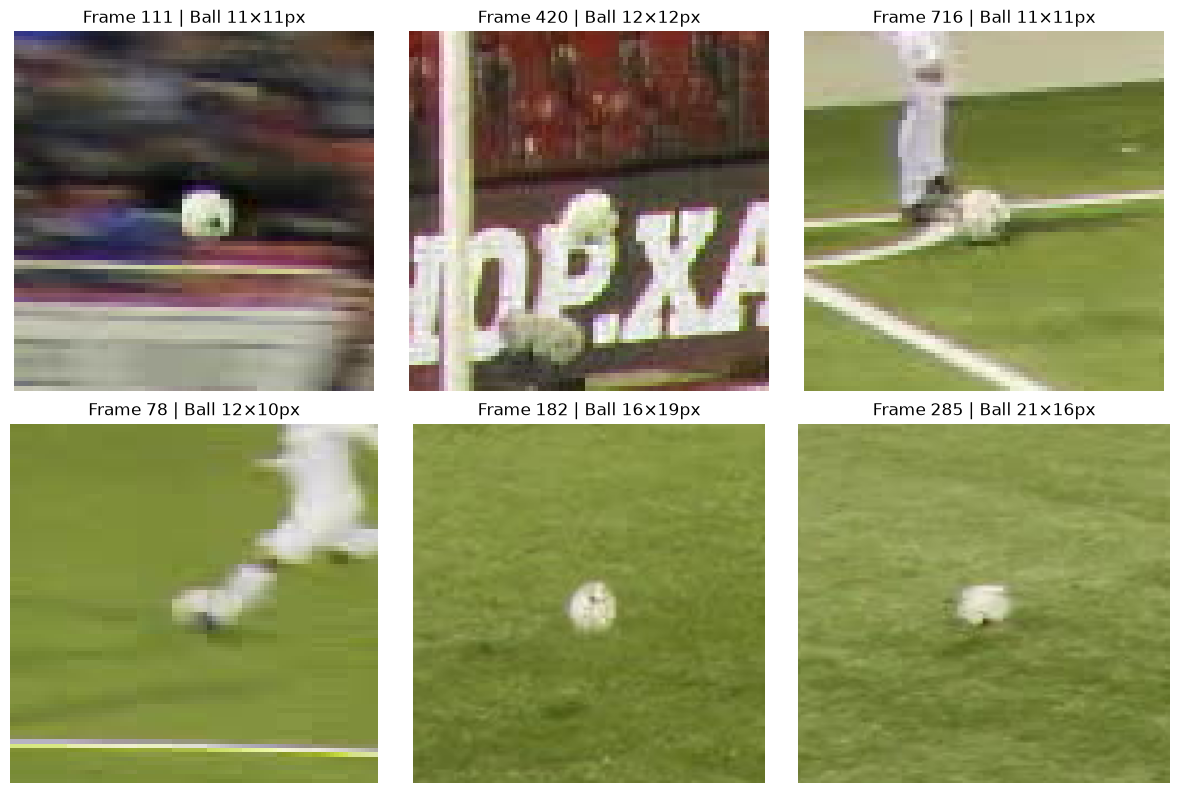

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):

    image_path = img_dir / f"{int(row['frame']):06d}.jpg"

    image = Image.open(image_path)

    x = int(row["x"])
    y = int(row["y"])
    w = int(row["width"])
    h = int(row["height"])

    pad = max(30, int(max(w, h) * 3))

    left = max(0, x - pad)
    top = max(0, y - pad)
    right = min(image.width, x + w + pad)
    bottom = min(image.height, y + h + pad)

    crop = image.crop(
        (left, top, right, bottom)
    )

    ax.imshow(crop)

    ax.set_title(
        f"Frame {int(row['frame'])} | "
        f"Ball {w}×{h}px"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import random
import pandas as pd

SEED = 42

# Copy so the original sequence_df remains unchanged
split_df = sequence_df.copy()

# Reproducible shuffle
rng = random.Random(SEED)

indices = list(split_df.index)
rng.shuffle(indices)

split_df = split_df.loc[indices].reset_index(drop=True)

# Calculate split sizes
n = len(split_df)

n_train = int(n * 0.70)
n_val = int(n * 0.15)

# Assign splits
split_df["split"] = "test"

split_df.loc[:n_train - 1, "split"] = "train"

split_df.loc[
    n_train:n_train + n_val - 1,
    "split"
] = "val"

print("Sequence split")
print("=" * 50)

print("Total sequences :", len(split_df))
print("Train           :", (split_df["split"] == "train").sum())
print("Validation      :", (split_df["split"] == "val").sum())
print("Test            :", (split_df["split"] == "test").sum())

Sequence split
Total sequences : 106
Train           : 74
Validation      : 15
Test            : 17


In [22]:
split_df[
    ["sequence", "ball_track_ids", "num_ball_tracks", "split"]
].sort_values(
    ["split", "sequence"]
).reset_index(drop=True)

,sequence,ball_track_ids,num_ball_tracks,split
0,SNMOT-065,"[24, 26]",2,test
1,SNMOT-099,[5],1,test
2,SNMOT-105,"[22, 25, 26]",3,test
3,SNMOT-111,[7],1,test
4,SNMOT-119,"[6, 26]",2,test
...,...,...,...,...
101,SNMOT-157,[3],1,val
102,SNMOT-158,[17],1,val
103,SNMOT-164,"[16, 17]",2,val
104,SNMOT-166,"[19, 20]",2,val


In [23]:
train_sequences = set(
    split_df.loc[split_df["split"] == "train", "sequence"]
)

val_sequences = set(
    split_df.loc[split_df["split"] == "val", "sequence"]
)

test_sequences = set(
    split_df.loc[split_df["split"] == "test", "sequence"]
)

print("Train ∩ Val  :", train_sequences & val_sequences)
print("Train ∩ Test :", train_sequences & test_sequences)
print("Val ∩ Test   :", val_sequences & test_sequences)

Train ∩ Val  : set()
Train ∩ Test : set()
Val ∩ Test   : set()


In [24]:
print(
    split_df.groupby("split")["num_ball_tracks"]
    .agg(["count", "sum", "mean"])
)

       count  sum      mean
split                      
test      17   24  1.411765
train     74   93  1.256757
val       15   22  1.466667


In [25]:
# Output directory structure

for split in ["train", "val", "test"]:
    (OUTPUT_ROOT / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (OUTPUT_ROOT / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

print("Output directories created:")
print(OUTPUT_ROOT)

for split in ["train", "val", "test"]:
    print(
        f"{split:5s}: "
        f"{(OUTPUT_ROOT / 'images' / split).exists()} | "
        f"{(OUTPUT_ROOT / 'labels' / split).exists()}"
    )

Output directories created:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_yolo
train: True | True
val  : True | True
test : True | True


In [26]:
from pathlib import Path
import shutil

def convert_sequence_to_yolo(seq_row, split):
    """
    Convert one SoccerNet sequence from MOT format
    to YOLO ball-detection format.
    """

    seq_dir = Path(seq_row["path"])

    img_dir = seq_dir / "img1"
    gt_file = seq_dir / "gt" / "gt.txt"

    ball_ids = set(seq_row["ball_track_ids"])

    # Read image dimensions
    width = None
    height = None

    seqinfo = seq_dir / "seqinfo.ini"

    for line in seqinfo.read_text(errors="ignore").splitlines():

        line = line.strip()

        if line.startswith("imWidth="):
            width = int(line.split("=")[1])

        elif line.startswith("imHeight="):
            height = int(line.split("=")[1])

    if width is None or height is None:
        raise ValueError(
            f"Could not determine image size: {seqinfo}"
        )

    # --------------------------------------------------
    # Read ball annotations
    # --------------------------------------------------

    frame_boxes = {}

    with gt_file.open(errors="ignore") as f:

        for line in f:

            parts = line.strip().split(",")

            if len(parts) < 6:
                continue

            frame = int(parts[0])
            track_id = int(parts[1])

            x = float(parts[2])
            y = float(parts[3])
            w = float(parts[4])
            h = float(parts[5])

            if track_id not in ball_ids:
                continue

            if w <= 0 or h <= 0:
                continue

            frame_boxes.setdefault(frame, []).append(
                (x, y, w, h)
            )

    # --------------------------------------------------
    # Process images
    # --------------------------------------------------

    image_count = 0
    box_count = 0

    images = sorted(img_dir.glob("*.jpg"))

    for image_path in images:

        frame = int(image_path.stem)

        # Unique filename prevents collisions
        new_name = f"{seq_row['sequence']}_{image_path.name}"

        output_image = (
            OUTPUT_ROOT
            / "images"
            / split
            / new_name
        )

        output_label = (
            OUTPUT_ROOT
            / "labels"
            / split
            / f"{Path(new_name).stem}.txt"
        )

        # Copy image
        shutil.copy2(
            image_path,
            output_image
        )

        # Create YOLO label
        with output_label.open("w") as label_file:

            for x, y, w, h in frame_boxes.get(frame, []):

                # MOT → YOLO center coordinates
                cx = x + w / 2
                cy = y + h / 2

                # Normalize
                cx /= width
                cy /= height
                w_norm = w / width
                h_norm = h / height

                label_file.write(
                    f"0 "
                    f"{cx:.8f} "
                    f"{cy:.8f} "
                    f"{w_norm:.8f} "
                    f"{h_norm:.8f}\n"
                )

                box_count += 1

        image_count += 1

    return image_count, box_count

In [27]:
def test_convert_sequence(seq_row, output_dir):
    seq_dir = Path(seq_row["path"])
    img_dir = seq_dir / "img1"
    gt_file = seq_dir / "gt" / "gt.txt"

    ball_ids = set(seq_row["ball_track_ids"])

    # Read image dimensions
    width = height = None

    for line in (seq_dir / "seqinfo.ini").read_text().splitlines():
        line = line.strip()

        if line.startswith("imWidth="):
            width = int(line.split("=")[1])

        elif line.startswith("imHeight="):
            height = int(line.split("=")[1])

    # Read ball annotations
    frame_boxes = {}

    with gt_file.open(errors="ignore") as f:
        for line in f:
            parts = line.strip().split(",")

            if len(parts) < 6:
                continue

            frame = int(parts[0])
            track_id = int(parts[1])

            if track_id not in ball_ids:
                continue

            x = float(parts[2])
            y = float(parts[3])
            w = float(parts[4])
            h = float(parts[5])

            frame_boxes.setdefault(frame, []).append(
                (x, y, w, h)
            )

    # Process images
    output_dir = Path(output_dir)
    images_dir = output_dir / "images"
    labels_dir = output_dir / "labels"

    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    image_count = 0
    box_count = 0

    for image_path in sorted(img_dir.glob("*.jpg")):

        frame = int(image_path.stem)

        new_name = f"{seq_row['sequence']}_{image_path.name}"

        shutil.copy2(
            image_path,
            images_dir / new_name
        )

        label_path = labels_dir / f"{Path(new_name).stem}.txt"

        with label_path.open("w") as f:

            for x, y, w, h in frame_boxes.get(frame, []):

                cx = (x + w / 2) / width
                cy = (y + h / 2) / height
                wn = w / width
                hn = h / height

                f.write(
                    f"0 {cx:.8f} {cy:.8f} "
                    f"{wn:.8f} {hn:.8f}\n"
                )

                box_count += 1

        image_count += 1

    return image_count, box_count

In [29]:
# Select SNMOT-170 for the conversion test

test_sequence = sequence_df[
    sequence_df["sequence"] == "SNMOT-170"
].iloc[0]

print("Sequence :", test_sequence["sequence"])
print("Ball IDs :", test_sequence["ball_track_ids"])
print("Path     :", test_sequence["path"])

Sequence : SNMOT-170
Ball IDs : [10]
Path     : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/soccernet/tracking/train/train/SNMOT-170


In [30]:
TEST_OUTPUT = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "processed"
    / "soccernet_ball_test"
)

images, boxes = test_convert_sequence(
    test_sequence,
    TEST_OUTPUT
)

print("Images converted:", images)
print("Ball boxes:", boxes)
print("Output:", TEST_OUTPUT)

Images converted: 750
Ball boxes: 600
Output: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/soccernet_ball_test


In [ ]:
label_path = (
    TEST_OUTPUT
    / "labels"
    / "SNMOT-170_000001.txt"
)

print(label_path.read_text())

In [32]:
label = label_path.read_text().strip().split()

cls = int(label[0])
cx = float(label[1])
cy = float(label[2])
w = float(label[3])
h = float(label[4])

cx_px = cx * 1920
cy_px = cy * 1080
w_px = w * 1920
h_px = h * 1080

x_px = cx_px - w_px / 2
y_px = cy_px - h_px / 2

print("Reconstructed:")
print(f"class  = {cls}")
print(f"x      = {x_px:.4f}")
print(f"y      = {y_px:.4f}")
print(f"width  = {w_px:.4f}")
print(f"height = {h_px:.4f}")

Reconstructed:
class  = 0
x      = 335.0000
y      = 511.0000
width  = 16.0000
height = 10.0000


In [33]:
from pathlib import Path
import shutil
import json
from collections import defaultdict

# ---------------------------------------------------------
# Production SoccerNet MOT → YOLO converter
# ---------------------------------------------------------

def read_sequence_info(seq_dir):
    """Read image dimensions and sequence length."""
    
    seqinfo_path = seq_dir / "seqinfo.ini"
    
    width = None
    height = None
    seq_length = None
    
    for line in seqinfo_path.read_text(errors="ignore").splitlines():
        line = line.strip()
        
        if line.startswith("imWidth="):
            width = int(line.split("=")[1])
            
        elif line.startswith("imHeight="):
            height = int(line.split("=")[1])
            
        elif line.startswith("seqLength="):
            seq_length = int(line.split("=")[1])
    
    if width is None or height is None or seq_length is None:
        raise ValueError(f"Invalid seqinfo.ini: {seqinfo_path}")
    
    return width, height, seq_length


def convert_sequence(seq_row, split):
    """
    Convert one SoccerNet sequence into YOLO detection format.
    
    Original MOT:
        frame, track_id, x, y, width, height, ...
    
    YOLO:
        class, cx, cy, width, height
    """
    
    seq_dir = Path(seq_row["path"])
    
    img_dir = seq_dir / "img1"
    gt_file = seq_dir / "gt" / "gt.txt"
    
    width, height, seq_length = read_sequence_info(seq_dir)
    
    ball_ids = set(seq_row["ball_track_ids"])
    
    # -----------------------------------------------------
    # Read ball annotations
    # -----------------------------------------------------
    
    frame_boxes = defaultdict(list)
    
    with gt_file.open(errors="ignore") as f:
        
        for line_number, line in enumerate(f, start=1):
            
            parts = line.strip().split(",")
            
            if len(parts) < 6:
                continue
            
            try:
                frame = int(parts[0])
                track_id = int(parts[1])
                
                x = float(parts[2])
                y = float(parts[3])
                w = float(parts[4])
                h = float(parts[5])
                
            except ValueError:
                continue
            
            # Only ball tracklets
            if track_id not in ball_ids:
                continue
            
            # Invalid dimensions
            if w <= 0 or h <= 0:
                continue
            
            # Basic boundary validation
            if x < 0 or y < 0:
                raise ValueError(
                    f"Negative bbox in {seq_dir.name}, "
                    f"line {line_number}"
                )
            
            if x + w > width or y + h > height:
                raise ValueError(
                    f"Out-of-image bbox in {seq_dir.name}, "
                    f"line {line_number}"
                )
            
            frame_boxes[frame].append(
                (x, y, w, h)
            )
    
    # -----------------------------------------------------
    # Output directories
    # -----------------------------------------------------
    
    images_out = OUTPUT_ROOT / "images" / split
    labels_out = OUTPUT_ROOT / "labels" / split
    
    images_out.mkdir(parents=True, exist_ok=True)
    labels_out.mkdir(parents=True, exist_ok=True)
    
    image_count = 0
    box_count = 0
    empty_label_count = 0
    
    # -----------------------------------------------------
    # Process every image
    # -----------------------------------------------------
    
    image_files = sorted(img_dir.glob("*.jpg"))
    
    for image_path in image_files:
        
        frame = int(image_path.stem)
        
        # Unique name across all sequences
        output_name = (
            f"{seq_row['sequence']}_{image_path.name}"
        )
        
        output_image = images_out / output_name
        
        output_label = (
            labels_out /
            f"{Path(output_name).stem}.txt"
        )
        
        # Prevent accidental overwrite
        if output_image.exists():
            raise FileExistsError(
                f"Duplicate output image: {output_image}"
            )
        
        if output_label.exists():
            raise FileExistsError(
                f"Duplicate output label: {output_label}"
            )
        
        # Copy image
        shutil.copy2(
            image_path,
            output_image
        )
        
        boxes = frame_boxes.get(frame, [])
        
        # Always create a label file.
        # Empty label = no annotated ball in this frame.
        with output_label.open("w") as f:
            
            if not boxes:
                empty_label_count += 1
            
            for x, y, w, h in boxes:
                
                # MOT top-left → YOLO center
                cx = x + w / 2
                cy = y + h / 2
                
                # Normalize
                cx /= width
                cy /= height
                w_norm = w / width
                h_norm = h / height
                
                # Final validation
                values = [cx, cy, w_norm, h_norm]
                
                if not all(0 <= v <= 1 for v in values):
                    raise ValueError(
                        f"Invalid YOLO coordinates in "
                        f"{output_label}: {values}"
                    )
                
                f.write(
                    f"0 "
                    f"{cx:.8f} "
                    f"{cy:.8f} "
                    f"{w_norm:.8f} "
                    f"{h_norm:.8f}\n"
                )
                
                box_count += 1
        
        image_count += 1
    
    return {
        "sequence": seq_row["sequence"],
        "split": split,
        "images": image_count,
        "ball_boxes": box_count,
        "empty_labels": empty_label_count,
        "ball_tracklets": len(ball_ids),
        "width": width,
        "height": height,
        "seq_length": seq_length
    }

In [ ]:
conversion_results = []

for split in ["train", "val", "test"]:
    
    sequences = split_df[
        split_df["split"] == split
    ]
    
    print()
    print("=" * 60)
    print(f"PROCESSING {split.upper()}")
    print("=" * 60)
    
    for i, (_, seq_row) in enumerate(
        sequences.iterrows(),
        start=1
    ):
        
        result = convert_sequence(
            seq_row,
            split
        )
        
        conversion_results.append(result)
        
        print(
            f"[{i:02d}/{len(sequences):02d}] "
            f"{result['sequence']} | "
            f"{result['images']} images | "
            f"{result['ball_boxes']} boxes"
        )

conversion_df = pd.DataFrame(conversion_results)

print()
print("=" * 60)
print("FULL CONVERSION COMPLETE")
print("=" * 60)

print(
    conversion_df.groupby("split")[
        ["images", "ball_boxes", "empty_labels", "ball_tracklets"]
    ].sum()
)


PROCESSING TRAIN
[01/74] SNMOT-076 | 750 images | 609 boxes
[02/74] SNMOT-194 | 750 images | 735 boxes
[03/74] SNMOT-131 | 750 images | 514 boxes
[04/74] SNMOT-125 | 750 images | 747 boxes
[05/74] SNMOT-165 | 750 images | 747 boxes
[06/74] SNMOT-069 | 750 images | 768 boxes
[07/74] SNMOT-117 | 750 images | 780 boxes
[08/74] SNMOT-103 | 750 images | 746 boxes
[09/74] SNMOT-106 | 750 images | 572 boxes
[10/74] SNMOT-112 | 750 images | 740 boxes
[11/74] SNMOT-110 | 750 images | 703 boxes
[12/74] SNMOT-113 | 750 images | 750 boxes
[13/74] SNMOT-126 | 750 images | 739 boxes
[14/74] SNMOT-193 | 750 images | 640 boxes
[38/74] SNMOT-060 | 750 images | 734 boxes
[39/74] SNMOT-199 | 750 images | 579 boxes
[40/74] SNMOT-169 | 750 images | 786 boxes
[41/74] SNMOT-066 | 750 images | 724 boxes
[42/74] SNMOT-154 | 750 images | 669 boxes
[43/74] SNMOT-128 | 750 images | 622 boxes
[44/74] SNMOT-188 | 750 images | 745 boxes
[45/74] SNMOT-139 | 750 images | 709 boxes
[46/74] SNMOT-191 | 750 images | 606